# **Lab 7(A) - Laplacian Filter (Solved)**

In [1]:
import cv2
import numpy as np
from IPython.display import Image, display
from matplotlib import pyplot as plt

plt.rc('text', usetex=False)

## Apply Laplacian Filter on Image to get Sharp Image

**Theory:** The Laplacian is a 2nd-derivative operator, so it highlights regions of rapid intensity change (edges, fine details) and flattens smooth regions.

Sharpened image: `g(x,y) = f(x,y) + c * ∇²f(x,y)`

* `c = -1` if the **centre** coefficient of the kernel is **negative** (kernel `[0,1,0],[1,-4,1],[0,1,0]`)
* `c = +1` if the **centre** coefficient is **positive**

> ⚠️ **Correction to the original code:** `img + laplacian_abs` is wrong for two reasons: (1) taking `abs()` throws away the sign of the Laplacian, so the details get added in the wrong direction; (2) `img` is `uint8`, so `+` wraps around (e.g. 250 + 10 = 4) instead of saturating. The solution below keeps the signed Laplacian (`float64`), applies the correct sign, and clips to 0-255.

### Part 1 - Manual Laplacian kernel with `cv2.filter2D`

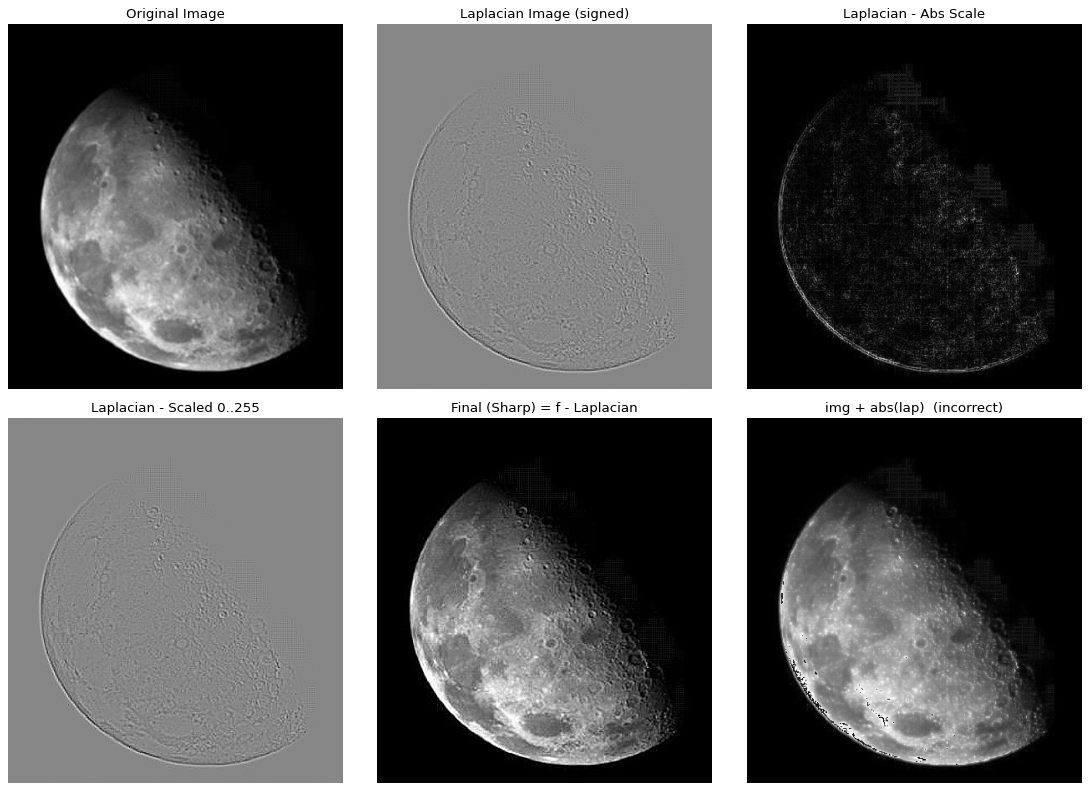

In [2]:
# ================ ( Laplacian Filter - Manual Kernel ) ===================
imgFile = "moon.jpg"

# 1. Load image in grayscale
img = cv2.imread(imgFile, 0)

# 2. Manual Laplacian kernel (4-neighbour: horizontal + vertical edges)
manual_kernel = np.array([
    [0,  1,  0],
    [1, -4,  1],
    [0,  1,  0]
], dtype=np.float32)

# 3. Apply the filter with CV_64F to keep negative values
laplacian_manual = cv2.filter2D(img, cv2.CV_64F, manual_kernel)

# 4. Absolute value -> 8-bit (for display only)
laplacian_abs = cv2.convertScaleAbs(laplacian_manual)

# 5. Scale Laplacian to 0-255 for a nicer display
lap_scaled = cv2.normalize(laplacian_manual, None, 0, 255, cv2.NORM_MINMAX).astype(np.uint8)

# 6. Sharpen: centre coefficient is NEGATIVE  ->  g = f - Laplacian
finalImage = np.clip(img.astype(np.float64) - laplacian_manual, 0, 255).astype(np.uint8)

# (the wrong way from the original code, kept for comparison)
wrongImage = img + laplacian_abs          # uint8 overflow + lost sign

plt.figure(figsize=(14, 10))
plt.subplot(231), plt.imshow(img, cmap='gray'),            plt.title('Original Image')
plt.subplot(232), plt.imshow(laplacian_manual, cmap='gray'), plt.title('Laplacian Image (signed)')
plt.subplot(233), plt.imshow(laplacian_abs, cmap='gray'),  plt.title('Laplacian - Abs Scale')
plt.subplot(234), plt.imshow(lap_scaled, cmap='gray'),     plt.title('Laplacian - Scaled 0..255')
plt.subplot(235), plt.imshow(finalImage, cmap='gray'),     plt.title('Final (Sharp) = f - Laplacian')
plt.subplot(236), plt.imshow(wrongImage, cmap='gray'),     plt.title('img + abs(lap)  (incorrect)')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

### Part 2 - Diagonal-aware kernel (8-neighbour)

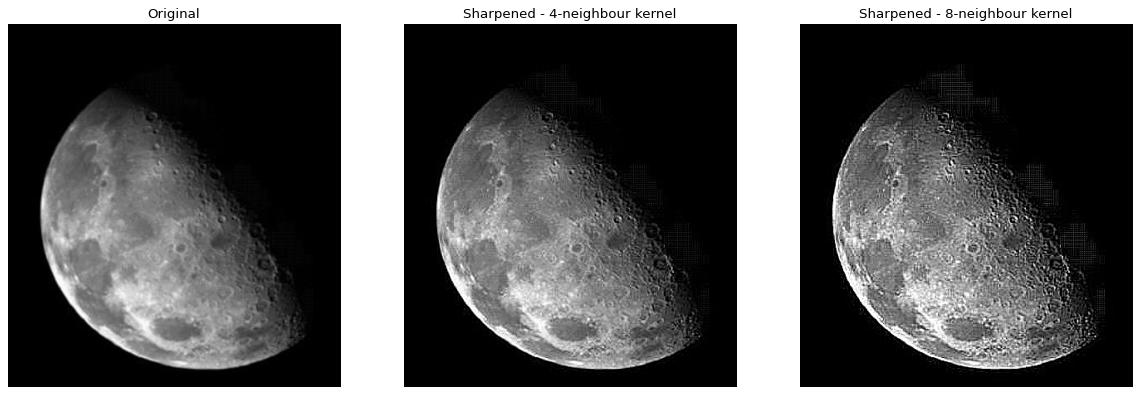

In [3]:
# Alternative kernel: detects diagonal edges as well (centre = -8)
kernel8 = np.array([
    [1,  1,  1],
    [1, -8,  1],
    [1,  1,  1]
], dtype=np.float32)

lap8 = cv2.filter2D(img, cv2.CV_64F, kernel8)
sharp8 = np.clip(img.astype(np.float64) - lap8, 0, 255).astype(np.uint8)

plt.figure(figsize=(15, 5))
plt.subplot(131), plt.imshow(img, cmap='gray'),    plt.title('Original')
plt.subplot(132), plt.imshow(finalImage, cmap='gray'), plt.title('Sharpened - 4-neighbour kernel')
plt.subplot(133), plt.imshow(sharp8, cmap='gray'), plt.title('Sharpened - 8-neighbour kernel')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

### Part 3 - Built-in `cv2.Laplacian` (with optional Gaussian blur to reduce noise)

Manual filter2D == cv2.Laplacian ? True


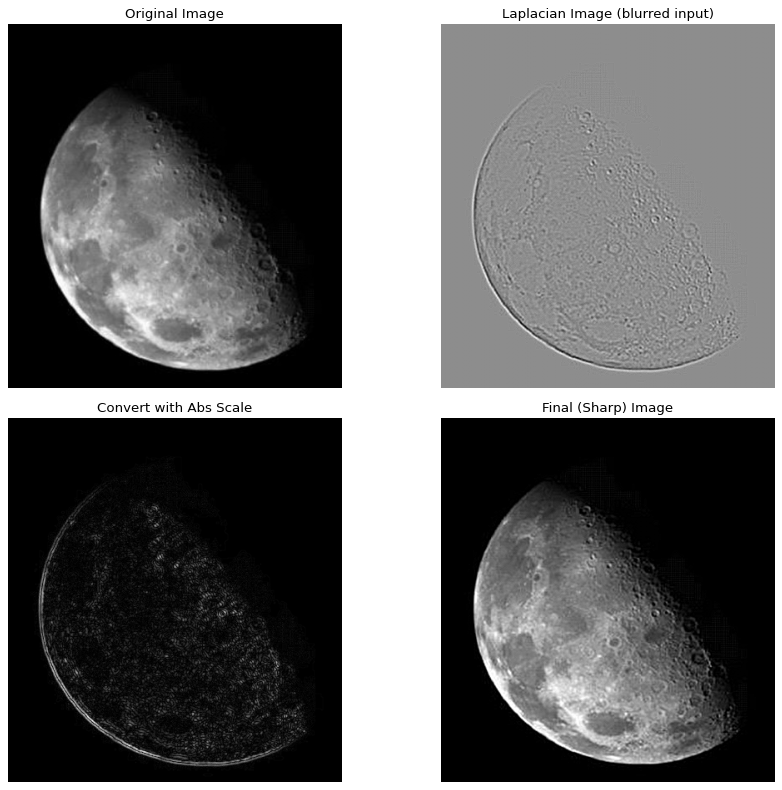

In [4]:
# ================== ( Laplacian Filter - Built-in ) ===============

# 1. Optional: Gaussian blur to reduce noise before the 2nd derivative
blurred = cv2.GaussianBlur(img, (3, 3), 0)

# 2. cv2.Laplacian with CV_64F (ksize=1 gives the same [0,1,0;1,-4,1;0,1,0] kernel)
laplacian = cv2.Laplacian(blurred, cv2.CV_64F, ksize=1)

# 3. 8-bit version for display
laplacian_8bit = cv2.convertScaleAbs(laplacian)

# 4. Sharpen: centre is negative -> subtract
finalImage2 = np.clip(img.astype(np.float64) - laplacian, 0, 255).astype(np.uint8)

# Same result, using OpenCV's saturated arithmetic
finalImage3 = cv2.addWeighted(img, 1.0, cv2.convertScaleAbs(laplacian), -1.0, 0)  # (abs version, for illustration)

plt.figure(figsize=(12, 10))
plt.subplot(221), plt.imshow(img, cmap='gray'),            plt.title('Original Image')
plt.subplot(222), plt.imshow(laplacian, cmap='gray'),      plt.title('Laplacian Image (blurred input)')
plt.subplot(223), plt.imshow(laplacian_8bit, cmap='gray'), plt.title('Convert with Abs Scale')
plt.subplot(224), plt.imshow(finalImage2, cmap='gray'),    plt.title('Final (Sharp) Image')
for ax in plt.gcf().axes: ax.axis('off')
plt.tight_layout()
plt.show()

# Check: manual kernel and cv2.Laplacian give the same Laplacian (no blur)
lap_cv = cv2.Laplacian(img, cv2.CV_64F, ksize=1)
print("Manual filter2D == cv2.Laplacian ?", np.allclose(lap_cv, laplacian_manual))

## Conclusion

| Step | Purpose |
|---|---|
| Laplacian (2nd derivative) | Highlights edges / fine details (crater rims on the moon) |
| `CV_64F` | Keeps negative values (needed for correct sharpening) |
| `convertScaleAbs` / normalize | Only for **display** of the Laplacian |
| `f - Laplacian` (centre negative) | Adds the details back to the original -> **sharper** image |
| Gaussian blur first | Reduces noise amplification (Laplacian is very noise-sensitive) |
| 8-neighbour kernel | Stronger sharpening, also responds to diagonal edges |